### Data Assembly 

- assemble a minimal **dev atlas**: pancreas + esophagus + stomach + bile duct (foregut epithelial).
- incorporate cancer data

In [ ]:
# Endodermal epithelial developmental reference (with pancreas labels preserved)
# - backed="r" for large files
# - metadata df with ['cell_id','major_trajectory','celltype_update','day',...]
# - includes pancreas + broader endodermal epithelium 
# - produces: adata_dev_endoderm.h5ad

import os, re
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as an

import matplotlib.pyplot as plt
from scipy import sparse

### **The Data - Qiu atlas** 
*A single-cell time-lapse of mouse prenatal development from gastrula to birth*

- Downloaded form [Qiu atlas](https://shendure-web.gs.washington.edu/content/members/cxqiu/public/backup/jax/download/adata/). It contains *11441407 cells x 24552 genes*; **note**: cell type and gene name information in specific .csv files

`.X in these .h5ad files is raw (or QC-filtered) counts, unnormalized and unlogged.`

>scRNAseq data

In [2]:
# .. sustitute '/home/jfpoyatos/Work/MNCN_24_25/' for your local directory 
INDIRdev = "/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/development"

# scRNAseq data - four datasets
files = [os.path.join(INDIRdev, "adata_JAX_dataset_1.h5ad"),
         os.path.join(INDIRdev, "adata_JAX_dataset_2.h5ad"),
         os.path.join(INDIRdev, "adata_JAX_dataset_3.h5ad"),
         os.path.join(INDIRdev, "adata_JAX_dataset_4.h5ad"),
         ]

> genes 

In [3]:
dfgenes = pd.read_csv(os.path.join(INDIRdev, "df_gene.csv"))
print(dfgenes.head())

# also useful:
print("")
print("Shape:",dfgenes.shape)          # rows, columns
print("Column names:",dfgenes.columns)      # column names
print("Sequence types:", dfgenes['gene_type'].unique())

print("")
type_counts = dfgenes["gene_type"].value_counts().sort_index()
print("Gene type counts:")
print(type_counts)

           Unnamed: 0             gene_id       gene_type gene_short_name  \
0  ENSMUSG00000051951  ENSMUSG00000051951  protein_coding            Xkr4   
1  ENSMUSG00000102343  ENSMUSG00000102343         lincRNA         Gm37381   
2  ENSMUSG00000025900  ENSMUSG00000025900  protein_coding             Rp1   
3  ENSMUSG00000025902  ENSMUSG00000025902  protein_coding           Sox17   
4  ENSMUSG00000104328  ENSMUSG00000104328         lincRNA         Gm37323   

    chr  
0  chr1  
1  chr1  
2  chr1  
3  chr1  
4  chr1  

Shape: (24552, 5)
Column names: Index(['Unnamed: 0', 'gene_id', 'gene_type', 'gene_short_name', 'chr'], dtype='object')
Sequence types: ['protein_coding' 'lincRNA' 'pseudogene']

Gene type counts:
gene_type
lincRNA            3611
protein_coding    20842
pseudogene           99
Name: count, dtype: int64


> cells - they have been annotated using markers described in Supplementary Table 12

In [4]:
dfcells = pd.read_csv(os.path.join(INDIRdev, "df_cell.csv"))
print(dfcells.head())

# also useful:
print(""), print("")
print("Shape:",dfcells.shape)        # rows, columns
print("Columns:",dfcells.columns)      # column names

                              Unnamed: 0                            cell_id  \
0  run_4_P2-01A.ATTCAAGCATGTTACGCAAG-0-0  run_4_P2-01A.ATTCAAGCATGTTACGCAAG   
1   run_4_P2-01A.CCGTCGATTTTATTCTGAG-0-0   run_4_P2-01A.CCGTCGATTTTATTCTGAG   
2  run_4_P2-01A.ATGGTAACTTAGCCGGTACC-0-0  run_4_P2-01A.ATGGTAACTTAGCCGGTACC   
3   run_4_P2-01A.CCGACCAATTTGCGAGGCA-0-0   run_4_P2-01A.CCGACCAATTTGCGAGGCA   
4   run_4_P2-01A.ATGCTTCCTAATGCCGCTT-0-0   run_4_P2-01A.ATGCTTCCTAATGCCGCTT   

    day  embryo_id experimental_batch        major_trajectory  \
0  E8.5  embryo_11              run_4  Neuroectoderm_and_glia   
1  E8.5  embryo_12              run_4                Mesoderm   
2  E8.5  embryo_12              run_4     Primitive_erythroid   
3  E8.5   embryo_8              run_4        Epithelial_cells   
4  E8.5   embryo_9              run_4                Mesoderm   

                           celltype_update  
0                     Dorsal telencephalon  
1  Lateral plate and intermediate mesoderm  

In [5]:
print("major trajectory #:",len(dfcells["major_trajectory"].unique()))
print("cell type #:",len(dfcells["celltype_update"].unique()))
dfcells["major_trajectory"].value_counts().sort_index()

major trajectory #: 26
cell type #: 190


major_trajectory
Adipocytes                            114478
B_cells                                44352
CNS_neurons                          2106206
Cardiomyocytes                         37205
Definitive_erythroid                 1033409
Endothelium                           312029
Ependymal_cells                        15396
Epithelial_cells                      524960
Eye_and_other                          93695
Hepatocytes                           289569
Intermediate_neuronal_progenitors     628251
Intestine                              51796
Lung_and_airway                        76732
Mast_cells                             23835
Megakaryocytes                         15129
Mesoderm                             3267338
Muscle_cells                          305003
Neural_crest_PNS_glia                 126743
Neural_crest_PNS_neurons              103999
Neuroectoderm_and_glia               1733663
Olfactory_sensory_neurons              42826
Oligodendrocytes                      

In [6]:
for traj, celltypes in dfcells.groupby("major_trajectory"):
    print(f"\n{traj}:")
    # get counts for this trajectory
    ct_counts = celltypes["celltype_update"].value_counts()
    for ct, n in ct_counts.items():
        print(f"  - {ct}: {n} cells")



Adipocytes:
  - Brown adipocyte cells: 80279 cells
  - Adipocyte progenitor cells: 19823 cells
  - Adipocyte cells (Cyp2e1+): 14376 cells

B_cells:
  - B cells: 43057 cells
  - B cell progenitors: 1295 cells

CNS_neurons:
  - Glutamatergic neurons: 725228 cells
  - GABAergic cortical interneurons: 603448 cells
  - GABAergic neurons: 376415 cells
  - Cajal-Retzius cells: 81803 cells
  - Thalamic neuronal precursors: 81788 cells
  - Spinal cord dorsal progenitors: 43382 cells
  - Neural progenitor cells (Ror1+): 33240 cells
  - Spinal cord motor neurons: 31398 cells
  - Cerebellar Purkinje cells: 26737 cells
  - Spinal cord ventral progenitors: 23904 cells
  - Cranial motor neurons: 23754 cells
  - Neural progenitor cells (Neurod1+): 23270 cells
  - Retinal ganglion cells: 11197 cells
  - Amacrine cells: 10061 cells
  - Amacrine/Horizontal precursor cells: 5155 cells
  - Neurons (Slc17a8+): 1957 cells
  - Cholinergic amacrine cells: 1426 cells
  - PV-containing retinal ganglion cells: 1

> Defining the developmental atlas

In [7]:
DF_PATH  = os.path.join(INDIRdev, "df_cell.csv")
OUT_PATH = os.path.join(INDIRdev, "adata_dev_endoderm.h5ad")

# Toggle: only pancreas vs full foregut / endoderm atlas
STRICT_PANCREAS_ONLY = False

# Columns in df_cell.csv
COL_CELLID   = "cell_id"
COL_MAJOR    = "major_trajectory"
COL_CELLTYPE = "celltype_update"
COL_DAY      = "day"

# We keep foregut-/endoderm-derived epithelia (pancreas/hepato-biliary/gut/lung)
# and optionally islets (non-epithelial endocrine reference).
ALLOW_MAJOR = {
    "Epithelial_cells",  # generic epithelial bins
    "Intestine",         # gut epithelium
    "Lung_and_airway",   # foregut respiratory epithelium
    "Hepatocytes",       # liver/hepatobiliary axis
    "Eye_and_other",     # used for Pancreatic islets in Qiu
}

# Pancreas-specific mapping preserved (for dev_state_pancreas)
PANCREAS_TYPE2STATE = {
    "Pancreatic acinar cells":  "acinar_or_tip",
    "Foregut epithelial cells": "ductal",      # ductal proxy
    "Pancreatic islets":        "non_epithelial_endocrine",
}

# Explicit list of cell types to INCLUDE IN THE ATLAS
# (names must match df_cell.csv exactly)
INCLUDE_CELLTYPES = {
    # Pancreas / hepatobiliary / foregut core (epithelial)
    "Pancreatic acinar cells",
    "Foregut epithelial cells",
    "Biliary epithelial cells",
    "Hepatocytes",

    # Optional non-epithelial endocrine reference
    "Pancreatic islets",

    # Gut epithelium (proximal vs distal)
    "Gut",
    "Midgut/Hindgut epithelial cells",
    "Intestinal goblet cells",
    "Intestinal enteroendocrine cells",

    # Lung & airway (anterior foregut)
    "Lung progenitor cells",
    "Lung cells (Eln+)",
    "Airway goblet cells",
    "Airway club cells",
    "Alveolar Type 1 cells",
    "Alveolar Type 2 cells",

    # Foregut-associated endocrine/epithelial organs
    "Thyroid gland cells",
    "Parathyroid epithelial cells",
    "Thymic epithelial cells",
}

# If you want strictly pancreas-only:
if STRICT_PANCREAS_ONLY:
    INCLUDE_CELLTYPES = {
        "Pancreatic acinar cells",
        "Pancreatic islets",
        "Foregut epithelial cells",
    }

# Coarse endoderm / epithelial categories for the broader tree
# Exact matches (main way)
ENDO_MAP_EXACT = {
    # Pancreas / hepatobiliary / foregut core
    "Pancreatic acinar cells":           "pancreas_acinar",
    "Foregut epithelial cells":          "pancreas_ductal_proxy",
    "Pancreatic islets":                 "pancreas_islet",
    "Biliary epithelial cells":          "biliary",
    "Hepatocytes":                       "liver_hepatocyte",

    # Foregut-associated endocrine/epithelial organs
    "Thyroid gland cells":               "foregut_other",
    "Parathyroid epithelial cells":      "foregut_other",
    "Thymic epithelial cells":           "foregut_other",

    # Gut epithelium (proximal vs distal)
    "Gut":                               "gut_epithelium_proximal_or_mixed",
    "Midgut/Hindgut epithelial cells":   "gut_epithelium_distal",
    "Intestinal goblet cells":           "gut_epithelium_distal",
    "Intestinal enteroendocrine cells":  "gut_epithelium_distal",

    # Lung & airway
    "Lung progenitor cells":             "lung_progenitor",
    "Lung cells (Eln+)":                 "lung_airway",
    "Airway goblet cells":               "lung_airway",
    "Airway club cells":                 "lung_airway",
    "Alveolar Type 1 cells":             "lung_airway",
    "Alveolar Type 2 cells":             "lung_airway",
}

# Substring fallbacks for robustness (everything lowercased)
ENDO_MAP_SUBSTR = [
    # Pancreas / hepatobiliary / foregut
    ("pancreatic acinar",     "pancreas_acinar"),
    ("foregut epithelial",    "pancreas_ductal_proxy"),
    ("islet",                 "pancreas_islet"),
    ("biliary",               "biliary"),
    ("hepatocyte",            "liver_hepatocyte"),

    # Foregut-associated endocrine/epithelial organs
    ("thyroid",               "foregut_other"),
    ("parathyroid",           "foregut_other"),
    ("thymic epithelial",     "foregut_other"),

    # Gut / intestine
    ("midgut",                "gut_epithelium_distal"),
    ("hindgut",               "gut_epithelium_distal"),
    ("intestinal",            "gut_epithelium_distal"),
    ("goblet",                "gut_epithelium_distal"),
    ("enteroendocrine",       "gut_epithelium_distal"),
    ("gut",                   "gut_epithelium_proximal_or_mixed"),

    # Lung & airway
    ("lung progenitor",       "lung_progenitor"),
    ("alveolar type 1",       "lung_airway"),
    ("alveolar type 2",       "lung_airway"),
    ("lung",                  "lung_airway"),
    ("airway goblet",         "lung_airway"),
    ("airway club",           "lung_airway"),
]

# Allowed endoderm / foregut categories after mapping
ALLOW_ENDO_CATEGORIES = {
    "pancreas_acinar",
    "pancreas_ductal_proxy",
    "pancreas_islet",                    # endocrine reference
    "biliary",
    "liver_hepatocyte",
    "foregut_other",
    "gut_epithelium_proximal_or_mixed",
    "gut_epithelium_distal",
    "lung_airway",
    "lung_progenitor",
}


In [8]:
# .. check
print("overlap:",len(set(dfcells[COL_CELLTYPE]) & INCLUDE_CELLTYPES))
print("proposed:",len(INCLUDE_CELLTYPES))

overlap: 18
proposed: 18


In [9]:
# some helper functions

def map_endo_category(celltype: str) -> str | None:
    """Map Qiu celltype to coarse endoderm category."""
    if celltype in ENDO_MAP_EXACT:
        return ENDO_MAP_EXACT[celltype]
    ct_low = celltype.lower()
    for substr, cat in ENDO_MAP_SUBSTR:
        if substr in ct_low:
            return cat
    return None

def classify_dev_tier(celltype: str, endo_cat: str | None) -> str:
    """
    dev_tier:
      - 'progenitor'  : foregut/endoderm progenitors
      - 'epithelial'  : committed epithelial derivatives
      - 'non_epithelial_endocrine' : e.g. islets (if kept)
    """
    ct_low = celltype.lower()

    if "islet" in ct_low:
        return "non_epithelial_endocrine"

    if endo_cat in {"foregut_progenitor", "pancreas_progenitor",
                    "hepatic_progenitor", "gut_progenitor", "lung_progenitor"}:
        return "progenitor"

    # fallback: anything mapped to a valid endoderm category but not tagged above
    if endo_cat in ALLOW_ENDO_CATEGORIES:
        return "epithelial"

    return "other"

In [10]:
# some utility functions

def strip_suffix(x: str) -> str:
    """
    Remove one or more trailing '-...'-style suffixes.
    E.g. '...-10' -> '...', '...-1-12' -> '...'.
    """
    return re.sub(r"(-[A-Za-z0-9]+)+$", "", str(x))

# This takes strings like "E18.5", "P0", "P3.5" and turns them into numeric developmental time:
# E18.5 → 18.5, P0 → 20.0. P3.5 → 23.5. A plain "17.0" → 17.0
# Idea: all postnatal stages are offset by +20 so they sit after all embryonic values on a single continuous axis.
# Anything that doesn’t match these patterns becomes NaN.
def parse_dev_day(x):
    """E18.5 -> 18.5 ; P0 -> 20.0+offset so postnatal > embryonic."""
    if pd.isna(x): return np.nan
    s = str(x).strip()
    m = re.match(r'^[Ee]\s*([0-9]+(?:\.[0-9]+)?)$', s)
    if m: return float(m.group(1))
    m = re.match(r'^[Pp]\s*([0-9]+(?:\.[0-9]+)?)$', s)
    if m: return 20.0 + float(m.group(1))
    m = re.match(r'^[0-9]+(?:\.[0-9]+)?$', s)
    if m: return float(s)
    return np.nan

> Define the final reference atlas

In [11]:
df = pd.read_csv(DF_PATH)  # df_cell.csv

for col in [COL_CELLID, COL_MAJOR, COL_CELLTYPE]:
    if col not in df.columns:
        raise ValueError(f"Metadata missing {col}. Found: {list(df.columns)[:12]}")

df[COL_CELLID] = df[COL_CELLID].astype(str)
df["cell_id_base"] = df[COL_CELLID].map(strip_suffix)

# 1) Restrict to relevant "major_trajectory" buckets (foregut / endodermal-ish)
df = df[df[COL_MAJOR].astype(str).isin(ALLOW_MAJOR)].copy()

# 2) Scope: pancreas-only vs broader foregut/endodermal atlas
if STRICT_PANCREAS_ONLY:
    keep_types = set(PANCREAS_TYPE2STATE.keys())
    df = df[df[COL_CELLTYPE].astype(str).isin(keep_types)].copy()
    # Map endo_category for these (should all hit ENDO_MAP_EXACT)
    df["endo_category"] = df[COL_CELLTYPE].astype(str).map(map_endo_category)
else:
    # broader: keep any cell that can be mapped into one of your endoderm/epithelial buckets
    df[COL_CELLTYPE] = df[COL_CELLTYPE].astype(str)
    df["endo_category"] = df[COL_CELLTYPE].map(map_endo_category)
    df = df[~df["endo_category"].isna()].copy()

print(f"Metadata rows kept (endodermal scope = {not STRICT_PANCREAS_ONLY}): {len(df)}")

# Minimal meta for merge (avoid _x/_y collisions)
meta_cols = [c for c in [COL_CELLID, "cell_id_base", COL_MAJOR, COL_CELLTYPE, COL_DAY] if c in df.columns]
extra_cols = ["endo_category"] if "endo_category" in df.columns else []
df_meta = df[meta_cols + extra_cols].drop_duplicates("cell_id_base")
df_meta = df_meta.set_index("cell_id_base")

# --- BACKED LOAD + MERGE ---
subsets = []

# Precompute metadata base-ID set once
meta_base_set = set(df_meta.index)

# Precompute the metadata columns we want to merge once
cols_wanted = [COL_MAJOR, COL_CELLTYPE]
if "endo_category" in df_meta.columns:
    cols_wanted.append("endo_category")
if COL_DAY in df_meta.columns:
    cols_wanted.append(COL_DAY)

right = df_meta[cols_wanted].copy()  # index = cell_id_base

for path in files:
    print(f"\n[backed] Opening {os.path.basename(path)} …")

    ad_b = sc.read_h5ad(path, backed="r")

    # 1) Work with obs_names as an array (no need for set)
    obs_names = ad_b.obs_names.astype(str)

    # 2) Compute base IDs once
    cell_id_base = pd.Index([strip_suffix(x) for x in obs_names],name="cell_id_base")

    # 3) Boolean mask: cells whose base IDs are in metadata
    mask = cell_id_base.isin(meta_base_set)

    n_keep = mask.sum()
    print(f"  cells in file: {ad_b.n_obs} | matching endoderm IDs: {n_keep}")

    if n_keep == 0:
        ad_b.file.close()
        continue

    # (Optional) quick debug example for run_25
    ex_run25 = [cid for cid in obs_names[mask] if "run_25_PD-12H_S384" in cid][:10]
    if ex_run25:
        print("Example run_25 matches:", ex_run25)

    # 4) Get the IDs to keep using the mask
    keep_ids = obs_names[mask]

    # 5) Load only those cells into memory
    ad_sub = ad_b[keep_ids].to_memory()
    ad_b.file.close()

    # 6) Attach cell_id_base for the kept cells
    ad_sub.obs["cell_id_base"] = cell_id_base[mask]

    # 7) Merge metadata from df_meta (already pre-sliced as 'right')
    ad_sub.obs = ad_sub.obs.merge(
        right,
        left_on="cell_id_base",
        right_index=True,
        how="left",
        suffixes=("", "_meta"),
    )

    # 8) Pancreas-only dev_state (will be NaN for non-pancreatic types)
    ad_sub.obs[COL_CELLTYPE] = ad_sub.obs[COL_CELLTYPE].astype("string")
    ad_sub.obs["dev_state_pancreas"] = (ad_sub.obs[COL_CELLTYPE].map(PANCREAS_TYPE2STATE).astype("category"))

    # 9) Union label: pancreas state first, else endo_category
    if "endo_category" in ad_sub.obs:
        ad_sub.obs["dev_state_union"] = ad_sub.obs["dev_state_pancreas"].astype("string")
        ad_sub.obs["dev_state_union"] = (
            ad_sub.obs["dev_state_union"]
            .fillna(ad_sub.obs["endo_category"].astype("string"))
            .astype("category")
        )

    # 10) dev_day from day / day_meta
    def choose_day_column(obs):
        if COL_DAY in obs.columns and obs[COL_DAY].notna().any():
            return COL_DAY
        elif f"{COL_DAY}_meta" in obs.columns and obs[f"{COL_DAY}_meta"].notna().any():
            return f"{COL_DAY}_meta"
        return None

    day_source = choose_day_column(ad_sub.obs)
    if day_source is not None:
        ad_sub.obs["dev_day"] = (
            ad_sub.obs[day_source]
            .astype("string")
            .map(parse_dev_day)
        )

    # 11) Track source file and store subset
    ad_sub.obs["source_file"] = os.path.basename(path)
    subsets.append(ad_sub)

if not subsets:
    raise RuntimeError(
        "No cells loaded after endoderm filtering—check label spellings in df.celltype_update."
    )

# --- CONCAT CELLS ---
adata_dev = an.concat(subsets, join="outer", index_unique=None)
adata_dev.var_names_make_unique()

# --- dev_tier: progenitor vs epithelial vs non_epithelial_endocrine ---
def _classify_row(row):
    celltype = str(row.get(COL_CELLTYPE, ""))
    endo_cat = row.get("endo_category", None)
    return classify_dev_tier(celltype, endo_cat)

adata_dev.obs["dev_tier"] = adata_dev.obs.apply(_classify_row, axis=1).astype("category")

# --- Ensure HDF5-safe dtypes for all string-like metadata columns
stringish_cols = [
    "major_trajectory",
    "celltype_update",
    "endo_category",
    "dev_state_pancreas",
    "dev_state_union",
    "dev_tier",
    "source_file",
]

for c in stringish_cols:
    if c in adata_dev.obs:
        dt = adata_dev.obs[c].dtype
        if not (
            isinstance(dt, pd.CategoricalDtype) or
            pd.api.types.is_string_dtype(dt)
        ):
            adata_dev.obs[c] = adata_dev.obs[c].astype("category")

# This function ensures that categorical categories become plain Python strings
def sanitize_obs_for_h5ad(A: an.AnnData) -> an.AnnData:
    obs = A.obs.copy()
    for c in obs.columns:
        dt = obs[c].dtype

        if isinstance(dt, pd.CategoricalDtype):
            cats = obs[c].cat.categories
            if pd.api.types.is_string_dtype(cats.dtype) or cats.dtype != object:
                obs[c] = obs[c].cat.rename_categories(cats.astype(object))

        elif pd.api.types.is_string_dtype(dt):
            obs[c] = obs[c].astype(object)

    A.obs = obs
    return A

adata_dev = sanitize_obs_for_h5ad(adata_dev)

# (optional) enforce object for known text columns
for c in ["major_trajectory", "celltype_update", "endo_category",
          "dev_state_pancreas", "dev_state_union", "dev_tier", "source_file"]:
    if c in adata_dev.obs and not isinstance(adata_dev.obs[c].dtype, pd.CategoricalDtype):
        adata_dev.obs[c] = adata_dev.obs[c].astype(object)

os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
adata_dev.write_h5ad(OUT_PATH, compression="lzf")
print("Saved:", OUT_PATH)

Metadata rows kept (endodermal scope = True): 456690

[backed] Opening adata_JAX_dataset_1.h5ad …
  cells in file: 2840130 | matching endoderm IDs: 25415

[backed] Opening adata_JAX_dataset_2.h5ad …
  cells in file: 2560869 | matching endoderm IDs: 27138

[backed] Opening adata_JAX_dataset_3.h5ad …
  cells in file: 2643980 | matching endoderm IDs: 114022

[backed] Opening adata_JAX_dataset_4.h5ad …
  cells in file: 3396428 | matching endoderm IDs: 290115
Example run_25 matches: ['run_25_PD-12H_S384.ATCAATACGTATAGACTAGG-1-12', 'run_25_PD-12H_S384.CAGATCAGTTTAGGATCTA-1-12', 'run_25_PD-12H_S384.CTCGCATGTTCGAGGAGTA-1-12', 'run_25_PD-12H_S384.ACGGCAATTCAAGCTTCAT-1-12', 'run_25_PD-12H_S384.GGTACGGATGTCCTAGAGG-1-12', 'run_25_PD-12H_S384.CCTGCTACTGTTCTGAATT-1-12', 'run_25_PD-12H_S384.GGTTGGCATTACTTACTTA-1-12', 'run_25_PD-12H_S384.GACCGTCATTATTACTCAT-1-12', 'run_25_PD-12H_S384.TATCATGAGTAGACTCAAGC-1-12', 'run_25_PD-12H_S384.GGTCAGTTTGGCCAGTCCG-1-12']
Saved: /home/jfpoyatos/Work/MNCN_24_25/Devel

balancing

In [12]:
def downsample_by(obs, key, max_per=4000, seed=13):
    idx = []
    for cat, sub in obs.groupby(key):
        keep_n = min(len(sub), max_per)
        idx.append(sub.sample(n=keep_n, random_state=seed).index)
    return np.concatenate(idx)

label_col = "dev_state_union"

print("Before balance:\n", adata_dev.obs[label_col].value_counts())

keep_idx = downsample_by(adata_dev.obs, key=label_col, max_per=4000, seed=13)
adata_dev_bal = adata_dev[keep_idx].copy()

print("\nAfter balance:\n", adata_dev_bal.obs[label_col].value_counts())

adata_dev_bal = adata_dev_bal.to_memory()
ENDO_OUT = os.path.join(INDIRdev, "adata_dev_endoderm_balanced.h5ad")
adata_dev_bal.write_h5ad(ENDO_OUT, compression="lzf")


Before balance:
 dev_state_union
liver_hepatocyte                    289569
gut_epithelium_distal                51380
lung_airway                          47744
lung_progenitor                      28988
gut_epithelium_proximal_or_mixed     21287
ductal                                6962
foregut_other                         3948
acinar_or_tip                         3747
biliary                               1742
non_epithelial_endocrine              1323
Name: count, dtype: int64


/tmp/ipykernel_2424412/2847849822.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for cat, sub in obs.groupby(key):



After balance:
 dev_state_union
gut_epithelium_distal               4000
ductal                              4000
lung_progenitor                     4000
lung_airway                         4000
gut_epithelium_proximal_or_mixed    4000
liver_hepatocyte                    4000
foregut_other                       3948
acinar_or_tip                       3747
biliary                             1742
non_epithelial_endocrine            1323
Name: count, dtype: int64


sanity check

In [13]:
adata_dev.obs[["endo_category","dev_tier","dev_state_union"]].value_counts()

endo_category                     dev_tier                  dev_state_union                 
liver_hepatocyte                  epithelial                liver_hepatocyte                    289569
gut_epithelium_distal             epithelial                gut_epithelium_distal                51380
lung_airway                       epithelial                lung_airway                          47744
lung_progenitor                   progenitor                lung_progenitor                      28988
gut_epithelium_proximal_or_mixed  epithelial                gut_epithelium_proximal_or_mixed     21287
pancreas_ductal_proxy             epithelial                ductal                                6962
foregut_other                     epithelial                foregut_other                         3948
pancreas_acinar                   epithelial                acinar_or_tip                         3747
biliary                           epithelial                biliary                

In [14]:
print(adata_dev_bal.obs["dev_state_union"].value_counts())
print('')
print('total cells:', np.sum(adata_dev_bal.obs["dev_state_union"].value_counts()))

dev_state_union
gut_epithelium_distal               4000
ductal                              4000
lung_progenitor                     4000
lung_airway                         4000
gut_epithelium_proximal_or_mixed    4000
liver_hepatocyte                    4000
foregut_other                       3948
acinar_or_tip                       3747
biliary                             1742
non_epithelial_endocrine            1323
Name: count, dtype: int64

total cells: 34760


#### Revise the developmental atlas once again

- 1/ run PCA/UMAP on adata_dev_bal, 
- 2/color by dev_state_union, and 
- 3/check visually that pancreas sits in the right spot along the foregut/gut manifold and that kidney/urothelial/squamous are clearly separate lobes.

(*one can directly restart the kernel here to avoid memory problems*; run imports at the beginning*)

In [1]:
knrestart = 1
if knrestart==1:
    import os
    import numpy as np
    import scanpy as sc
    import anndata as an
    import matplotlib.pyplot as plt
    from scipy import sparse
    
    # .. paths 
    commonpath = "/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/"
    # .. balanced dataset
    DEV_PATH    = os.path.join(commonpath, "development/adata_dev_endoderm_balanced.h5ad")
    adata_dev_bal    = an.read_h5ad(DEV_PATH)

In [3]:
label_col = "dev_state_union"
adata_dev_bal.obs[label_col].value_counts()

dev_state_union
gut_epithelium_distal               4000
ductal                              4000
lung_progenitor                     4000
lung_airway                         4000
gut_epithelium_proximal_or_mixed    4000
liver_hepatocyte                    4000
foregut_other                       3948
acinar_or_tip                       3747
biliary                             1742
non_epithelial_endocrine            1323
Name: count, dtype: int64

Using scanpy, note:
- sc.pp.* = preprocessing functions
These modify an AnnData object (filtering cells/genes, normalization, log-transform, HVG selection, scaling, regressions, etc.)
- sc.tl.* = tools
Higher-level algorithms like PCA, neighbors, UMAP, Leiden clustering, diffusion maps, PAGA, marker gene tests…
- sc.pl.* = plotting
UMAP plots, violin plots, gene ranking plots, heatmaps, dotplots, etc.

In [4]:
# Filter genes expressed in too few cells
# For each gene (each column), Scanpy counts how many cells have a non-zero expression.
# If that number < 10, the gene is thrown out completely. Why? Genes expressed in only a handful of cells are unreliable (lots of technical noise),
# unhelpful for global structure (they can create spurious “distance spikes”).
sc.pp.filter_genes(adata_dev_bal, min_cells=10)

# Looks at each gene’s average expression and variability across cells.
# Uses the Seurat v3 method to decide which genes vary more than expected at their mean expression level.
# Stores the result in adata_dev_bal.var["highly_variable"] as a boolean: True = this gene is an HVG
# 'seurat_v3': Gene variability increases with mean expression for technical reasons.
# Seurat v3 models this mean–variance relationship and picks genes that are more variable than expected for their mean.
# It’s a robust way to prioritize genes that actually contribute biological structure, not just “highly expressed = highly variable.”
sc.pp.highly_variable_genes(adata_dev_bal, n_top_genes=3000, flavor="seurat_v3")

# subset to HVGs
# adata_dev_bal.var["highly_variable"] is a boolean mask (per-gene).
# Number of cells: unchanged. Number of genes: 3000 (this is a typical numnber).
# The next steps (PCA, neighbors, UMAP, clustering) are faster and more robust when they focus on informative genes.
# This is standard scRNA-seq practice: downstream analysis happens in HVG space.
adata_dev_bal = adata_dev_bal[:, adata_dev_bal.var["highly_variable"]].copy()

# Scale - Standardize each gene across cells to mean 0 and variance 1, and clip extreme values.
sc.pp.scale(adata_dev_bal, max_value=10)
sc.tl.pca(adata_dev_bal, svd_solver="arpack", n_comps=50)

# Take the top 25 PCs (not all 50).
# For each cell, find the 20 nearest neighbors in that 25-PC space.
# Build a graph where edges connect nearest neighbors. This graph captures local similarity:
# if two cells are very similar → they become neighbors. if two cells differ strongly → distant in graph
# The KNN graph is your “connectivity backbone.”
sc.pp.neighbors(adata_dev_bal, n_neighbors=20, n_pcs=25)

#  UMAP takes the neighbor graph and computes a 2D embedding that preserves local neighborhoods and also global manifolds.
# Key parameter: min_dist=0.3-Controls clustering tightness:
#   0.1 → tight clusters, sharp boundaries (good for discrete tissue types)
#   0.3 → smoother manifolds (better for developmental trajectories)
#   0.5 → very spread-out; trajectories look like loose curves
# UMAP outputs: adata.obsm["X_umap"]: the 2D coordinates for each cell.
sc.tl.umap(adata_dev_bal, min_dist=0.3)

/home/jfpoyatos/miniconda3/envs/plasticity/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [5]:
print('total cells after balancing:', adata_dev_bal.shape[0], '    total genes after filtering', adata_dev_bal.shape[1])

total cells after balancing: 34760     total genes after filtering 3000


#### Figure S1

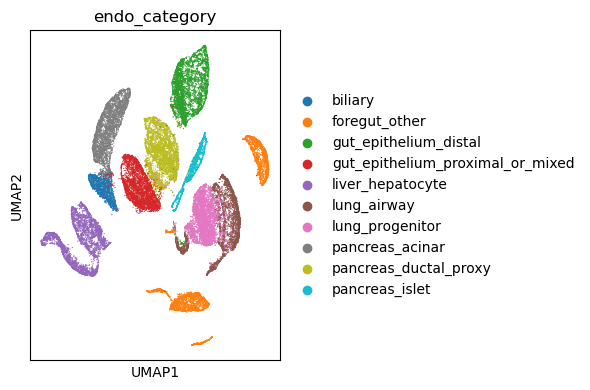

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))

sc.pl.umap(
    adata_dev_bal,
    color="endo_category",
    legend_loc="right margin", #"on data"
    frameon=True,
    size=3,
    ax=ax,               # <-- Scanpy draws into your axis
    show=False           # <-- don't let Scanpy open a new figure
)

plt.tight_layout()
plt.show()

- **Liver–biliary block (purple + dark blue).**
This is one of the nicest clusters in the plot, compact, coherent, and with a small biliary peninsula touching hepatocytes.
Biologically: Biliary → hepatocyte is a well-known continuum. A reviewer will look at this and nod.

- **Gut epithelium (distal = green; proximal = red).**
This separation is exactly what you'd expect:
distal (midgut/hindgut) more dorsal/top
proximal (duodenum/mixed gut) more central
The relative orientation is meaningless but the distance between them is correct.

- **Lung / airway / progenitor (brown + pink).**
You see:
a lung progenitor cluster (pink) sitting near
airway/alveolar (brown/purple-ish)
This captures the progenitor→mature axis cleanly.
This is your only developmental trajectory in the atlas — and it's surprisingly well-behaved.

- **Pancreas (acinar = grey; ductal proxy = yellow; islet = cyan).**
This is the smallest but most telling part:
acinar: tight grey cluster
ductal proxy: yellow island next to biliary and gut
islet: turquoise island sitting far away (correct — endocrine ≠ epithelial)
Pancreas sits between:
hepatobiliary
proximal gut
foregut-other
Which is exactly where it belongs developmentally.

- **Foregut_other (orange).**
These are thyroid/parathyroid/thymus epithelia.
They cluster cleanly and far from gut/lung/liver, which again is what you want.


### **The data - Burdziak cancer**
*Epigenetic plasticity cooperates with cell-cell interactions to direct pancreatic tumorigenesis*

*Single-cell analyses on normal, inflamed, premalignant, and malignant tissues in autochthonous models -experimental systems that develop tumors spontaneously within the organism, mimicking natural disease processes- of pancreatic cancer.*


- ProgressionCohort.h5ad: scanpy anndata object containing both raw and normalized counts for all Progression Cohort epithelial cells. 
    - **Raw counts are available in the .raw attribute**. **Normalized counts are un-logged**, and may be logged with base 2 and a pseudocount of 0.1 to recapitulate results in the paper. 
    - The .obs attribute contains cell clusters (coarse Phenograph clusters), batch (i.e. sample ID), and condition (N1-N2 or K1-K6, as described in the paper). 
    - The .obsm attribute provides PC coordinates ("X_PCA") and tSNE coordinates ("X_EMBED").

`.X in this .h5ad file is normalized but unlogged`

In [2]:
INDIRcan = "/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/pdac" 
INdata_can = os.path.join(INDIRcan, "GSE207938_ProgressionCohort.h5ad")

In [3]:
adata_cancer = sc.read_h5ad(INdata_can, backed="r")

print("Cells:", adata_cancer.n_obs, "Genes:", adata_cancer.n_vars)
print("OBS columns:", adata_cancer.obs.columns.tolist()[:20])

Cells: 28131 Genes: 16826
OBS columns: ['batch', 'condition', 'cluster']


In [ ]:
adata_cancer.obs

,batch,condition,cluster,epi_score
120703424252788_DACD394_Kate_plus,DACD394_Kate_plus,K1,0,19.874283
120703436605797_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,36.073220
120703436909853_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,34.452284
120703454952236_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,26.712270
120726896892262_DACD394_Kate_plus,DACD394_Kate_plus,K1,5,5.158195
...,...,...,...,...
241106402626286_DACD550_kate_plus,DACD550_kate_plus,N1,2,-4.427245
241114562127587_DACD550_kate_plus,DACD550_kate_plus,N1,2,-5.558278
241114576730845_DACD550_kate_plus,DACD550_kate_plus,N1,9,0.692000
241114607893403_DACD550_kate_plus,DACD550_kate_plus,N1,2,-3.752480


: 

Note here:
- N1 and N2 are normal ductal cells; N2 does not differ in lineage identity from N1
- N2 just differs in its inflamatory and regenerative state

In [4]:
# Unique (batch, condition) pairs
pairs = adata_cancer.obs[['batch', 'condition']].drop_duplicates()
print(pairs)

                                                   batch condition
120703424252788_DACD394_Kate_plus      DACD394_Kate_plus        K1
120726897159011_DACD406_Kate_plus      DACD406_Kate_plus        K1
120703409351982_DACD407_Kate_plus      DACD407_Kate_plus        K2
120703409343852_DAC_C263_EPI                DAC_C263_EPI      K1.5
120703423506158_DACC963_mKate_plus    DACC963_mKate_plus        K6
120703409567540_D396_EPI                        D396_EPI      K1.5
120703436633844_DACD404_Kate_plus      DACD404_Kate_plus        K2
120703436409581_DAC_DI143_Epi              DAC_DI143_Epi        K3
120772949134053_DACC963PT_Kate_plus  DACC963PT_Kate_plus        K5
120726911604597_DACD403_Kate_plus      DACD403_Kate_plus        N2
120703423765940_Ag-PDAC-PT-Kate          Ag-PDAC-PT-Kate        K5
120703409055966_DACD351_Kate_plus      DACD351_Kate_plus        K1
120703436678893_DAC_C301-EPI_2            DAC_C301-EPI_2        K4
120703424350126_DACC963LIVERmet          DACC963LIVERmet      

Here, 
- Kate_plus = cells that express the epithelial lineage reporter. This enriches specifically for epithelial-derived cells throughout N1 → K6.
- EPI = These are epithelial-enriched samples but the exact method (reporter vs antibody vs microdissection) may differ slightly.

> checking about whether cells are epithelial

In [5]:
adata_cancer.var_names

Index(['0610007P14RIK', '0610009B22RIK', '0610009L18RIK', '0610009O20RIK',
       '0610010F05RIK', '0610010K14RIK', '0610012G03RIK', '0610030E20RIK',
       '0610033M10RIK', '0610037L13RIK',
       ...
       'ZW10', 'ZWILCH', 'ZWINT', 'ZXDB', 'ZXDC', 'ZYG11A', 'ZYG11B', 'ZYX',
       'ZZEF1', 'ZZZ3'],
      dtype='object', length=16826)

Epithelial markers:

- EPCAM	- Epithelial Cell Adhesion Molecule; involved in cell adhesion and signaling. It's often used as a marker for epithelial cells.
- KRT8	- Keratin 8; a type of intermediate filament protein that is typically expressed in simple epithelial tissues.
- KRT18	- Keratin 18; another keratin associated with simple epithelial cells and commonly used in identifying tumors of epithelial origin.
- KRT19	- Keratin 19; this keratin is primarily found in simple epithelium and is often used in cancer research.
- CDH1	- Cadherin 1; also known as E-cadherin, it's a protein that plays a crucial role in cell adhesion within epithelial tissues.

In [6]:
# Define canonical epithelial markers (uppercase, since your var_names look like that)
epi_markers = ["EPCAM", "KRT8", "KRT18", "KRT19", "CDH1"] 
epi_markers_present = [g for g in epi_markers if g in adata_cancer.var_names]
print("Epithelial markers present:", epi_markers_present)


Epithelial markers present: ['EPCAM', 'KRT8', 'KRT18', 'KRT19', 'CDH1']


>epifiltered out

In [7]:
adata_cancer = adata_cancer.to_memory()
adata_cancer.file.close()

Is sparse matrix: True


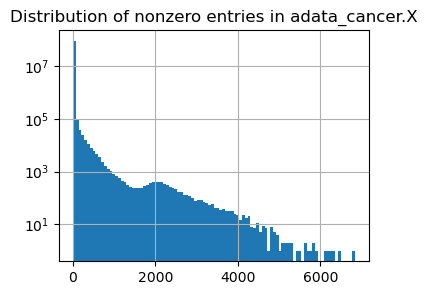

In [8]:
X = adata_cancer.X
is_sparse = sparse.issparse(X)
print("Is sparse matrix:", is_sparse)

if is_sparse:
    vals = X.data
else:
    vals = X[X > 0]

plt.figure(figsize=(4,3))
plt.hist(vals, bins=100)
plt.yscale("log")
plt.title("Distribution of nonzero entries in adata_cancer.X")
plt.grid()
plt.show()

In [9]:
adata_cancer.X.min(), adata_cancer.X.max(),adata_cancer.raw.X.min(), adata_cancer.raw.X.max()

(0.0, 6833.936, 0.0, 46624.0)

In [10]:
# Score epithelial program for all cells
if len(epi_markers_present) < 2:
    print("Too few epithelial markers present; skipping epithelial gating.")
    adata_epi = adata_cancer.copy()
else:
    # 2) Score epithelial program for all cells
    # mean(target genes) minus mean(control genes) per cell.
    sc.tl.score_genes(
        adata_cancer,
        gene_list=epi_markers_present,
        score_name="epi_score",
        use_raw=False # use adata.X, not adata.raw.X
    )

    print("epi_score summary:")
    print(adata_cancer.obs["epi_score"].describe())

    # 3) Choose a mild threshold:
    #    keep cells in the top 70% of epi_score
    drop_fraction = 0.30
    thresh = np.quantile(adata_cancer.obs["epi_score"], drop_fraction)
    print(f"Using epi_score >= {thresh:.3f} (keep top 70% epithelial by score)")

    epi_mask = adata_cancer.obs["epi_score"] >= thresh
    print("Cells before epithelial gate:", adata_cancer.n_obs)
    print("Cells after epithelial gate:", int(epi_mask.sum()))

    adata_epi = adata_cancer[epi_mask].copy()

print("Epithelial subset:", adata_epi.n_obs, "cells")


epi_score summary:
count    28131.000000
mean        16.070864
std         15.601848
min        -12.155810
25%          4.030074
50%         14.443037
75%         24.919104
max        114.292354
Name: epi_score, dtype: float64
Using epi_score >= 6.315 (keep top 70% epithelial by score)
Cells before epithelial gate: 28131
Cells after epithelial gate: 19692
Epithelial subset: 19692 cells


- Positive score → epithelial genes expressed higher than matched controls
- Zero-ish → no epithelial signal
- Negative → epithelial genes suppressed

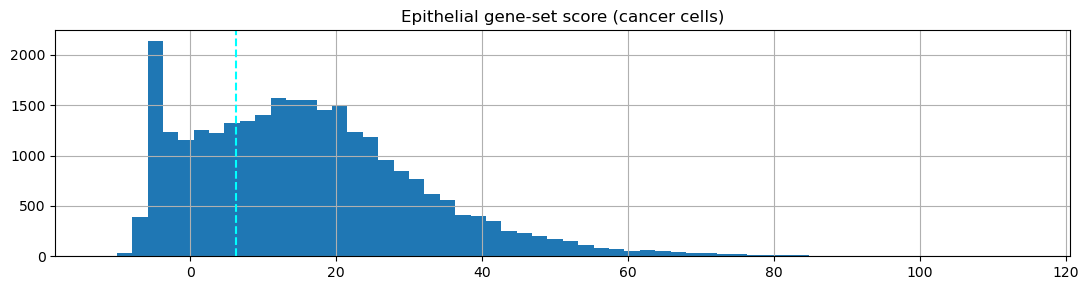

In [11]:
fig, ax = plt.subplots(figsize=(11,3))
ax.hist(adata_cancer.obs["epi_score"], bins=60)
ax.axvline(thresh, linestyle="--", linewidth=1.5,color="cyan")
ax.set_title("Epithelial gene-set score (cancer cells)")
plt.tight_layout()
plt.grid()
plt.show()


In [12]:
low_epi = adata_cancer[adata_cancer.obs["epi_score"] < thresh].copy()

# Look at some canonical non-epithelial markers
immune_markers = ["PTPRC", "CD3D", "CD68", "LYZ"]
fibro_markers  = ["COL1A1", "COL1A2", "PDGFRA", "ACTA2"]
endo_markers   = ["PECAM1", "KDR", "VWF"]
emt_markers    = ["VIM", "ZEB1", "SNAI1", "SNAI2"]

An overview of the various markers above 

## Immune Markers

| Marker   | Description                                       |
|----------|---------------------------------------------------|
| **PTPRC**  | Protein Tyrosine Phosphatase Receptor Type C; also known as **CD45**, it's a pan-leukocyte marker involved in regulating T and B cell receptor signaling. |
| **CD3D**   | CD3 Delta; part of the T-cell receptor complex, essential for T-cell activation and signaling. |
| **CD68**   | A macrophage-specific marker; it is involved in phagocytosis and is often used to identify macrophages in tissues. |
| **LYZ**    | Lysozyme; an enzyme with antimicrobial properties, typically found in various immune cells as well as epithelial tissues, playing roles in innate immunity. |

### Role in the Immune System:
These markers help identify different immune cell populations and assess immune responses. PTPRC is crucial for T and B cell functions, while CD3D indicates T cell activation. CD68 is used to identify macrophages, and LYZ plays a part in innate defense.



## Fibroblast Markers

| Marker   | Description                                       |
|----------|---------------------------------------------------|
| **COL1A1** | Collagen Type I Alpha 1; the primary component of extracellular matrix (ECM) in connective tissues, crucial for structural integrity. |
| **COL1A2** | Collagen Type I Alpha 2; works alongside COL1A1 to form collagen fibers essential for tissue structure. |
| **PDGFRA** | Platelet-Derived Growth Factor Receptor Alpha; involved in the regulation of fibroblast activation and proliferation. |
| **ACTA2**  | Alpha-Smooth Muscle Actin; a marker of myofibroblasts, which are activated fibroblasts contributing to wound healing and fibrosis. |

### Role in Fibroblasts:
These markers are indicative of fibroblast activity and functionality within connective tissues. COL1A1 and COL1A2 are critical for ECM structure, while PDGFRA is involved in fibroblast growth, and ACTA2 identifies myofibroblasts, important during wound healing.


## Endothelial Markers

| Marker   | Description                                       |
|----------|---------------------------------------------------|
| **PECAM1** | Platelet Endothelial Cell Adhesion Molecule 1; important for endothelial cell-cell junctions and leukocyte transmigration. |
| **KDR**    | Kinase Insert Domain Receptor; also known as **VEGF receptor 2**, essential in angiogenesis and endothelial cell proliferation. |
| **VWF**    | von Willebrand Factor; involved in blood coagulation and also plays a role in endothelial health and function. |

### Role in Endothelial Cells:
These markers are specific to endothelial cells lining blood vessels. PECAM1 supports cell adhesion and junction integrity, KDR is vital for blood vessel formation, and VWF contributes to hemostasis.


## EMT Markers

| Marker   | Description                                       |
|----------|---------------------------------------------------|
| **VIM**    | Vimentin; an intermediate filament protein involved in cellular structure and signaling, representing mesenchymal cells during EMT. |
| **ZEB1**   | Zinc Finger E-box Binding Homeobox 1; a transcription factor that promotes EMT by repressing epithelial markers. |
| **SNAI1**  | Snail Family Transcriptional Repressor 1; also acts as a transcription factor promoting EMT through downregulation of E-cadherin. |
| **SNAI2**  | Snail Family Transcriptional Repressor 2; similar to SNAI1, it's involved in promoting EMT and influencing cell migration. |

### Role in EMT:
These markers are associated with the process of epithelial-mesenchymal transition, a key mechanism in development, wound healing, and cancer metastasis. VIM signifies mesenchymal cell identity, while ZEB1 and SNAI proteins regulate the transition from an epithelial to a mesenchymal state.




immune markers present: ['PTPRC', 'CD3D', 'CD68']


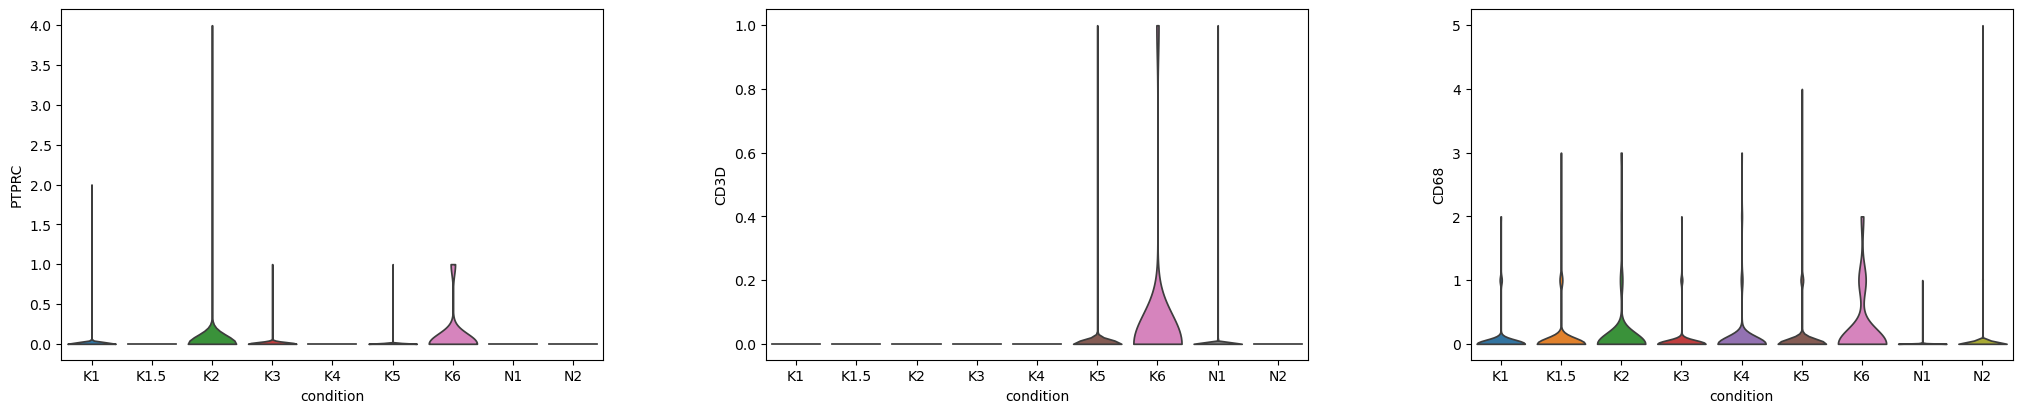


fibro markers present: ['COL1A1', 'COL1A2', 'PDGFRA', 'ACTA2']


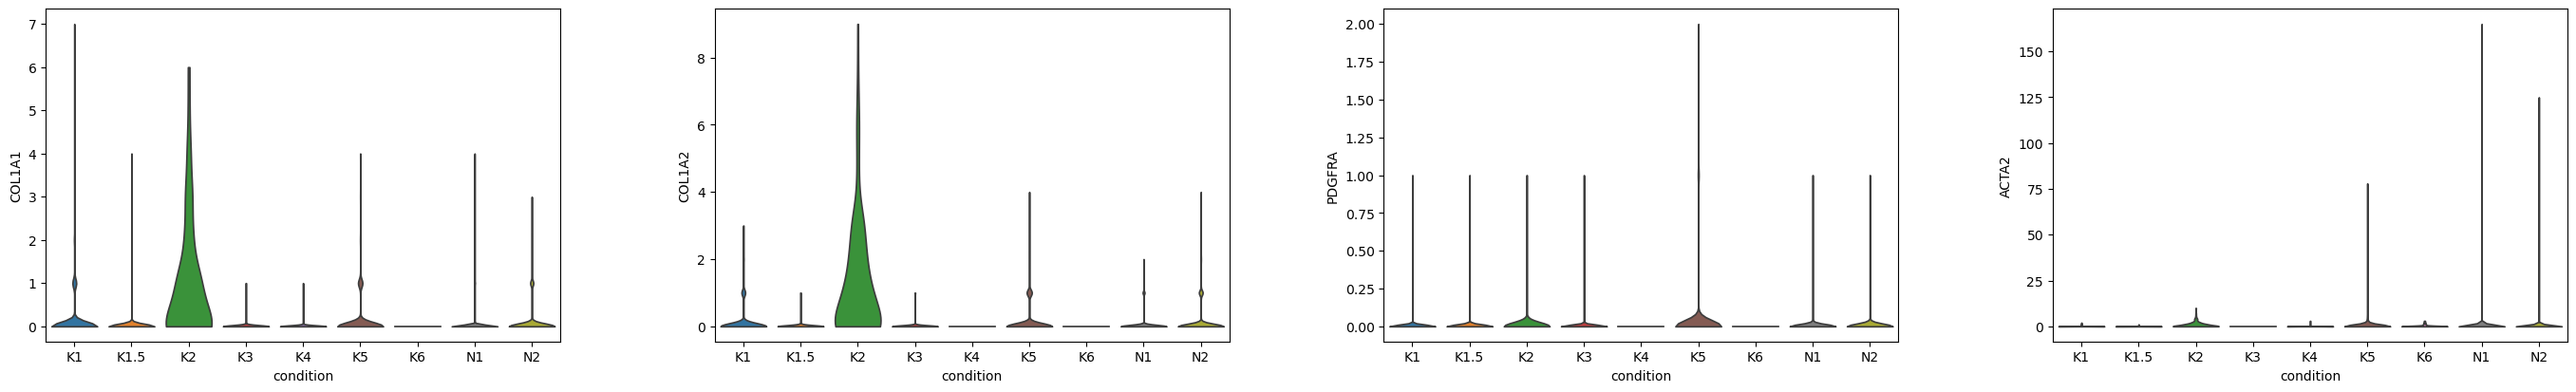


endo markers present: ['PECAM1', 'KDR', 'VWF']


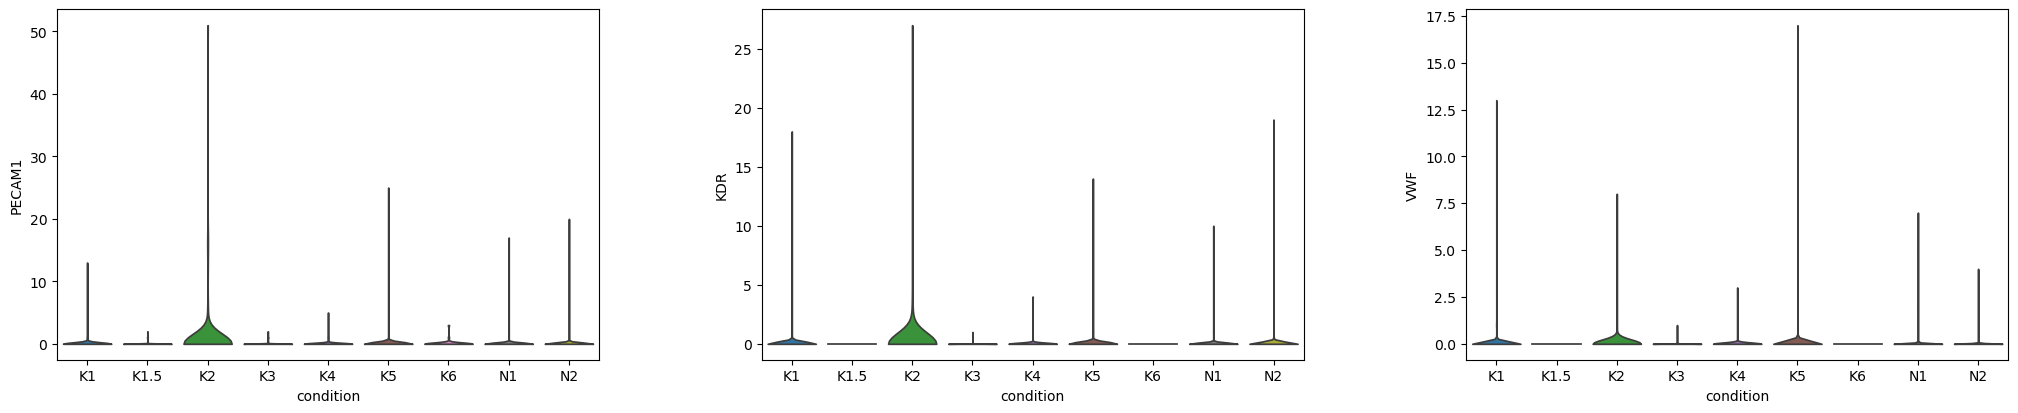


emt markers present: ['VIM', 'ZEB1', 'SNAI1', 'SNAI2']


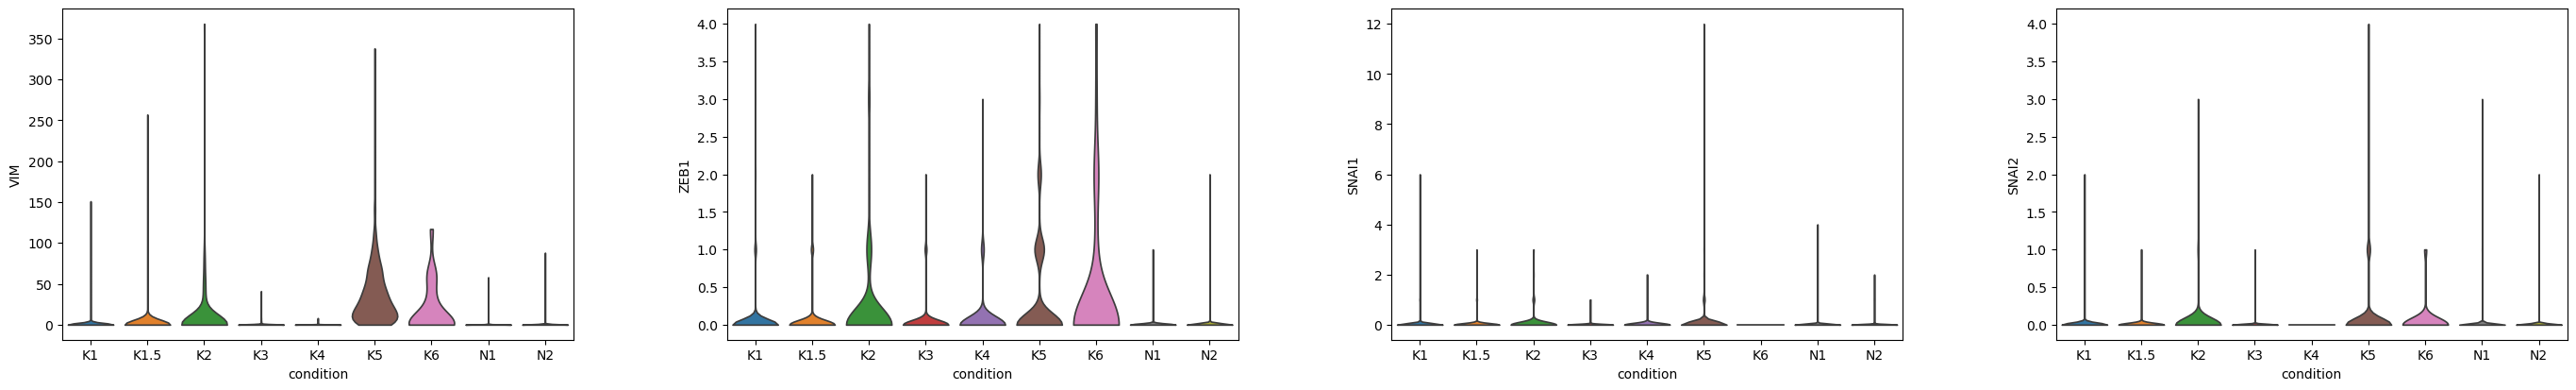

In [13]:
for panel, genes in [
    ("immune", immune_markers),
    ("fibro", fibro_markers),
    ("endo",  endo_markers),
    ("emt",   emt_markers),
]:
    present = [g for g in genes if g in low_epi.var_names]
    print(f"\n{panel} markers present:", present)
    if present:
        sc.pl.violin(low_epi, keys=present, groupby="condition", stripplot=False)


Given the project goal and the dataset origin:
- Do not apply the epi_score gate.

Keep the full 28,131 cells for the MLM.
Use the epi score as a diagnostic, not a hard filter:
you can plot UMAP colored by epi_score to see where low-epi cells sit,
if later you clearly identify a small immune/fibro cluster, you can surgically remove it by marker/cluster, not by 1D threshold.

So your pipeline for now:
- Skip the line where you subset to adata_epi. Just keep adata_cancer as is.


> *If after a first round of embeddings you clearly see non-malignant outliers (immune/fibro clusters), then we tighten with a more targeted filter. But right now, a blind “drop 30%” on a dataset that was already epithelial-enriched is more likely to hurt than help.* (I work below with adata_epifilterout instead of adata_epi)

In [18]:
adata_epifilterout = adata_cancer.copy()

In [19]:
# Coarse annotation (ductal / transitional / malignant_ductal)
COND2STATE = {
    "N1": "ductal",
    "N2": "ductal",
    "K1": "transitional",
    "K1.5": "transitional",
    "K2": "transitional",
    "K3": "transitional",
    "K4": "transitional",
    "K5": "malignant_ductal",
    "K6": "malignant_ductal",
}
adata_epifilterout.obs["cancer_state"] = adata_epifilterout.obs["condition"].map(COND2STATE).astype("category")

print("\nCounts by normalized condition:")
print(adata_epifilterout.obs["condition"].value_counts().sort_index())
print("\nCounts by coarse state:")
print(adata_epifilterout.obs["cancer_state"].value_counts(dropna=False))


Counts by normalized condition:
condition
K1      4503
K1.5    2476
K2      2079
K3      3338
K4      1254
K5      5364
K6      3491
N1      3225
N2      2401
Name: count, dtype: int64

Counts by coarse state:
cancer_state
transitional        13650
malignant_ductal     8855
ductal               5626
Name: count, dtype: int64


In [20]:
adata_epifilterout.obs

,batch,condition,cluster,epi_score,cancer_state
120703424252788_DACD394_Kate_plus,DACD394_Kate_plus,K1,0,19.874283,transitional
120703436605797_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,36.073220,transitional
120703436909853_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,34.452284,transitional
120703454952236_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,26.712270,transitional
120726896892262_DACD394_Kate_plus,DACD394_Kate_plus,K1,5,5.158195,transitional
...,...,...,...,...,...
241106402626286_DACD550_kate_plus,DACD550_kate_plus,N1,2,-4.427245,ductal
241114562127587_DACD550_kate_plus,DACD550_kate_plus,N1,2,-5.558278,ductal
241114576730845_DACD550_kate_plus,DACD550_kate_plus,N1,9,0.692000,ductal
241114607893403_DACD550_kate_plus,DACD550_kate_plus,N1,2,-3.752480,ductal


Note here:
- N1 and N2 are normal ductal cells; N2 does not differ in lineage identity from N1
- N2 just differs in its inflamatory and regenerative state

In [22]:
# Optional, derived column (don’t use unless you explicitly want a single 'N')
def collapse_N(x): return "N" if x in {"N1","N2"} else x
adata_epifilterout.obs["condition_collapsed"] = adata_epifilterout.obs["condition"].map(collapse_N)


# Keep an ordering that preserves N1 and N2 separately
progression_order = [c for c in ["N1","N2","K1","K1.5","K2","K3","K4","K5","K6"]
                     if c in adata_epifilterout.obs["condition"].unique()]
print("\nProgression order (keeping N1/N2):", progression_order)

# Basic normalization
#sc.pp.normalize_total(adata_epifilterout, target_sum=1e4)
#sc.pp.log1p(adata_epifilterout)
#adata_epifilterout.layers["counts"] = adata_epifilterout.X.copy()

# Always materialize fully before writing
adata_epifilterout = adata_epifilterout.to_memory()

print(adata_epifilterout)  # should show n_vars > 0
print("X dtype:", adata_epifilterout.X.dtype)
print("Layers:", adata_epifilterout.layers.keys())


#os.makedirs("data/Mouse/can", exist_ok=True)
CANCER_OUT = "data/pdac/burdziak_epifilterout_kept_N1_N2.h5ad"
adata_epifilterout.write_h5ad(CANCER_OUT, compression="lzf")
print("\nSaved:", CANCER_OUT)


Progression order (keeping N1/N2): ['N1', 'N2', 'K1', 'K1.5', 'K2', 'K3', 'K4', 'K5', 'K6']
AnnData object with n_obs × n_vars = 28131 × 16826
    obs: 'batch', 'condition', 'cluster', 'epi_score', 'cancer_state', 'condition_collapsed'
    obsm: 'X_EMBED', 'X_PCA'
X dtype: float32
Layers: KeysView(Layers with keys: )

Saved: data/pdac/burdziak_epifilterout_kept_N1_N2.h5ad


In [23]:
adata_epifilterout.obs

,batch,condition,cluster,epi_score,cancer_state,condition_collapsed
120703424252788_DACD394_Kate_plus,DACD394_Kate_plus,K1,0,19.874283,transitional,K1
120703436605797_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,36.073220,transitional,K1
120703436909853_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,34.452284,transitional,K1
120703454952236_DACD394_Kate_plus,DACD394_Kate_plus,K1,1,26.712270,transitional,K1
120726896892262_DACD394_Kate_plus,DACD394_Kate_plus,K1,5,5.158195,transitional,K1
...,...,...,...,...,...,...
241106402626286_DACD550_kate_plus,DACD550_kate_plus,N1,2,-4.427245,ductal,N
241114562127587_DACD550_kate_plus,DACD550_kate_plus,N1,2,-5.558278,ductal,N
241114576730845_DACD550_kate_plus,DACD550_kate_plus,N1,9,0.692000,ductal,N
241114607893403_DACD550_kate_plus,DACD550_kate_plus,N1,2,-3.752480,ductal,N


In [24]:
# confirm raw exists
assert adata_epifilterout.raw is not None, "Cancer AnnData has no .raw matrix"
adata_epifilterout.X = adata_epifilterout.raw.X.copy() # use raw counts for downstream
print("Using .raw counts for downstream analysis.")

Using .raw counts for downstream analysis.


UMAP analysis as before

In [25]:
# 1) filter genes expressed in too few cells
sc.pp.filter_genes(adata_epifilterout, min_cells=10)

# 2) find HVGs
sc.pp.highly_variable_genes(adata_epifilterout,n_top_genes=3000,flavor="seurat_v3")

# 3) subset to HVGs (note the .var)
adata_epifilterout = adata_epifilterout[:, adata_epifilterout.var["highly_variable"]].copy()

# 4) scale
sc.pp.scale(adata_epifilterout, max_value=10)

/home/jfpoyatos/miniconda3/envs/plasticity/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [26]:
sc.tl.pca(adata_epifilterout, svd_solver="arpack", n_comps=50)
sc.pp.neighbors(adata_epifilterout, n_neighbors=20, n_pcs=25)
sc.tl.umap(adata_epifilterout, min_dist=0.3)

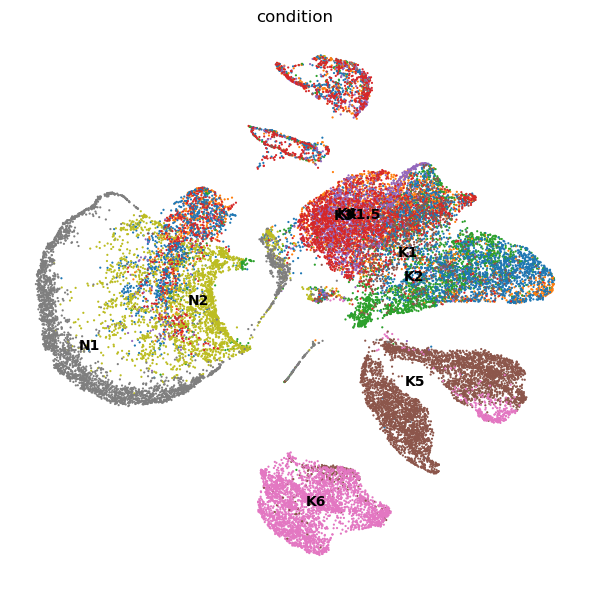

In [27]:
fig, ax = plt.subplots(figsize=(6, 6))

sc.pl.umap(adata_epifilterout,color="condition",legend_loc="on data",frameon=False,size=10, ax=ax,show=False)           
# <-- Scanpy draws into your axis # <-- don't let Scanpy open a new figure
plt.tight_layout()
plt.show()

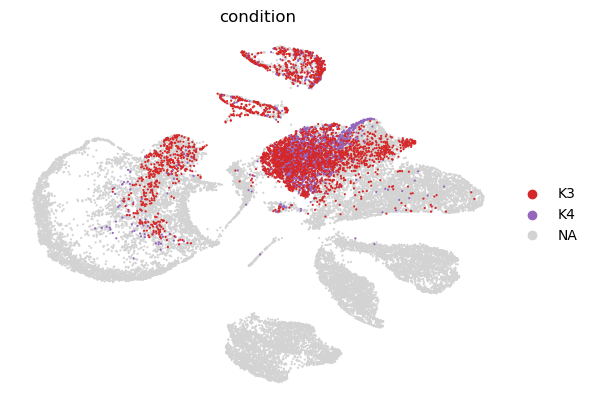

In [ ]:
sc.pl.umap(adata_epifilterout,color="condition",groups=["K3", "K4"],frameon=False,size=10)

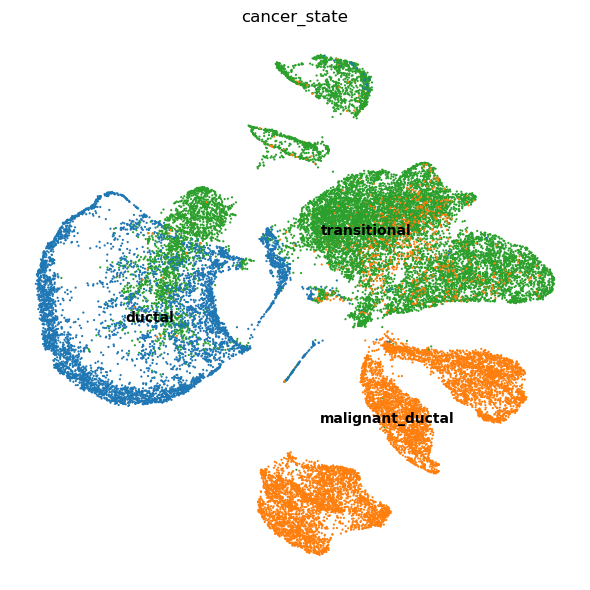

In [29]:
fig, ax = plt.subplots(figsize=(6, 6))

sc.pl.umap(adata_epifilterout,color="cancer_state",legend_loc="on data",frameon=False,size=10,ax=ax,show=False)
plt.tight_layout()
plt.show()


In [30]:
# Quick sanity checks (won't crash if already true, but will tell you what's missing)
assert "epi_score" in adata_epifilterout.obs.columns, "Missing adata_epifilterout.obs['epi_score']"
assert "X_umap" in adata_epifilterout.obsm.keys(), "Missing UMAP coordinates in adata_epifilterout.obsm['X_umap']"


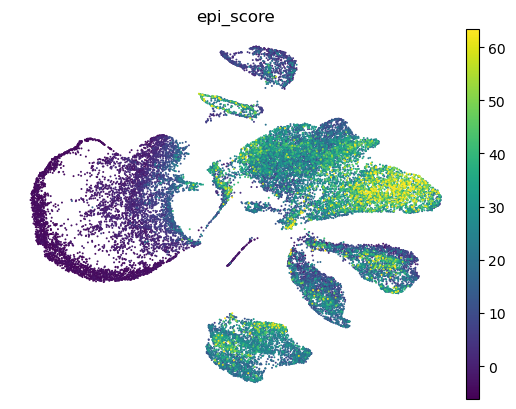

In [31]:
# Overlay epi_score on the existing UMAP
# vmin = "p1" --> robust scaling: clip extreme low/high outliers
sc.pl.umap(adata_epifilterout,color="epi_score",cmap="viridis",size=8,frameon=False,vmin="p1",vmax="p99",show=True)

#### Figure S2

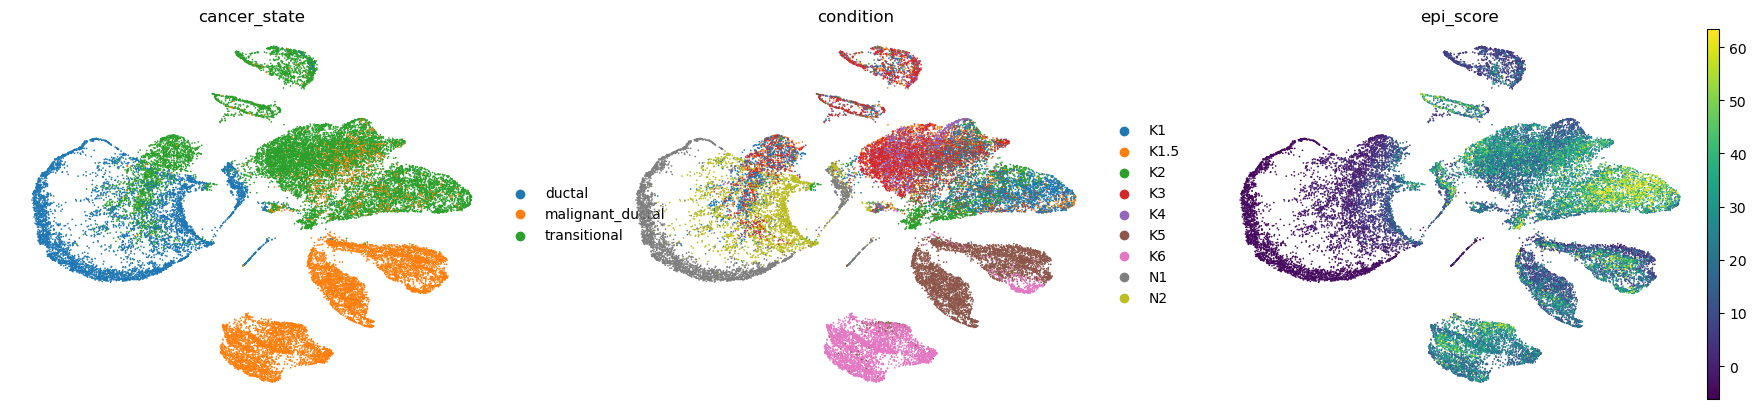

In [32]:
# side-by-side with your existing annotations (cancer_state, condition)
sc.pl.umap(
    adata_epifilterout,
    color=["cancer_state", "condition", "epi_score"],
    ncols=3,
    size=6,
    frameon=False,
    vmin="p1",
    vmax="p99"
)